In [1]:
import os, sys, time
from pathlib import Path
PROJECT = Path(r"C:\Users\hp\Documents\teliport_prototype")
os.chdir(PROJECT / "notebooks")
sys.path.insert(0, str(PROJECT / "src"))
%load_ext autoreload
%autoreload 2

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from cmapss_data import SUBSETS

PROC = PROJECT / "data" / "processed"
MODELS = PROJECT / "models"
REPORTS = PROJECT / "reports"
FIG_DIR = REPORTS / "figures"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("Working dir:", Path.cwd())

Working dir: C:\Users\hp\Documents\teliport_prototype\notebooks


In [2]:
%%writefile ../src/modeling.py
"""RUL modeling utilities: metrics, engine-level cross-validation, LightGBM training."""
from __future__ import annotations

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import GroupKFold

CRITICAL_RUL = 30          # "act now" zone used for weighting and critical-zone metrics
LGB_PARAMS = dict(n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
                  random_state=42, n_jobs=-1, verbose=-1)


# ---------------- metrics ----------------
def nasa_score(y_true, y_pred):
    """Official PHM08 score: late predictions (d > 0) are punished harder than early ones."""
    d = np.asarray(y_pred, float) - np.asarray(y_true, float)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_pred, float) - np.asarray(y_true, float)) ** 2)))


def evaluate(y_true, y_pred, critical=CRITICAL_RUL):
    y, p = np.asarray(y_true, float), np.asarray(y_pred, float)
    crit_true, crit_pred = y <= critical, p <= critical
    tp = int((crit_true & crit_pred).sum())
    return {
        "n": len(y),
        "RMSE": round(rmse(y, p), 2),
        "MAE": round(float(np.mean(np.abs(p - y))), 2),
        "NASA_score": round(nasa_score(y, p), 1),
        f"RMSE_RUL<={critical}": round(rmse(y[crit_true], p[crit_true]), 2) if crit_true.any() else np.nan,
        "critical_recall": round(tp / max(int(crit_true.sum()), 1), 3),
        "critical_precision": round(tp / max(int(crit_pred.sum()), 1), 3),
        "late_pred_%": round(100 * float(np.mean(p - y > 10)), 1),   # >10 cycles too optimistic
    }


# ---------------- training helpers ----------------
def make_lgbm(**overrides):
    return lgb.LGBMRegressor(**{**LGB_PARAMS, **overrides})


def sample_weights(rul, critical=CRITICAL_RUL, w=2.0):
    """Mild-imbalance handling: near-failure rows are rarer, so they count double."""
    return np.where(np.asarray(rul) <= critical, w, 1.0)


def val_rows(df, min_cycle=20, max_rul=150):
    """Rows that look like real test engines: some history, and within planning horizon."""
    return df[(df["cycle"] >= min_cycle) & (df["RUL"] <= max_rul)]


def fit_model(df, features, make_model, cap, weighted=True):
    model = make_model()
    y = df["RUL"].clip(upper=cap)
    if weighted:
        model.fit(df[features], y, sample_weight=sample_weights(df["RUL"]))
    else:
        model.fit(df[features], y)
    return model


def predict(model, df, features):
    return np.clip(model.predict(df[features]), 0, None)


def cross_validate(df, features, make_model, cap, weighted=True, n_splits=5):
    """GroupKFold by engine: no engine ever appears in both train and validation."""
    parts = []
    for fold, (a, b) in enumerate(GroupKFold(n_splits=n_splits).split(df, groups=df["unit"])):
        model = fit_model(df.iloc[a], features, make_model, cap, weighted)
        v = val_rows(df.iloc[b])
        parts.append(pd.DataFrame({"unit": v["unit"].to_numpy(), "cycle": v["cycle"].to_numpy(),
                                   "fold": fold, "y_true": v["RUL"].to_numpy(),
                                   "y_pred": predict(model, v, features)}))
    oof = pd.concat(parts, ignore_index=True)
    return evaluate(oof["y_true"], oof["y_pred"]), oof

Writing ../src/modeling.py


In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from modeling import cross_validate, make_lgbm, fit_model, predict, evaluate, rmse

tr = pd.read_pickle(PROC / "train_FD001.pkl")
F = joblib.load(MODELS / "preprocessor_FD001.joblib").feature_names_
CAP = 125

candidates = {
    "Constant (mean RUL)":      (lambda: DummyRegressor(strategy="mean"), False),
    "Ridge regression":         (lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)), False),
    "LightGBM":                 (make_lgbm, False),
    "LightGBM + imbalance wts": (make_lgbm, True),
}
rows = []
for name, (mk, weighted) in candidates.items():
    t0 = time.time()
    m, _ = cross_validate(tr, F, mk, CAP, weighted=weighted)
    rows.append({"model": name, **m, "secs": round(time.time() - t0, 1)})
baselines = pd.DataFrame(rows).set_index("model")
baselines.to_csv(REPORTS / "cv_baselines_fd001.csv")
baselines

,n,RMSE,MAE,NASA_score,RMSE_RUL<=30,critical_recall,critical_precision,late_pred_%,secs
model,,,,,,,,,
Constant (mean RUL),14738,44.97,38.35,6334540.8,72.38,0.000,0.000,52.2,0.3
Ridge regression,14738,19.03,15.45,89973.4,12.09,0.727,0.950,35.7,1.0
LightGBM,14738,13.06,9.24,36412.9,3.38,0.920,0.962,13.6,11.3
LightGBM + imbalance wts,14738,12.98,9.17,36014.5,3.25,0.927,0.956,13.3,11.2


In [4]:
rows = []
for fd in SUBSETS:
    trd = pd.read_pickle(PROC / f"train_{fd}.pkl")
    Fd = joblib.load(MODELS / f"preprocessor_{fd}.joblib").feature_names_
    for cap in (115, 125, 135):
        m, _ = cross_validate(trd, Fd, make_lgbm, cap, weighted=True)
        rows.append({"subset": fd, "cap": cap, "cv_RMSE": m["RMSE"], "cv_RMSE_RUL<=30": m["RMSE_RUL<=30"],
                     "cv_late_pred_%": m["late_pred_%"]})
        print(fd, cap, "done", flush=True)
cap_table = pd.DataFrame(rows).pivot(index="cap", columns="subset")
cap_table.to_csv(REPORTS / "cv_cap_ablation.csv")
cap_table

FD001 115 done
FD001 125 done
FD001 135 done
FD002 115 done
FD002 125 done
FD002 135 done
FD003 115 done
FD003 125 done
FD003 135 done
FD004 115 done
FD004 125 done
FD004 135 done


cv_RMSE                      cv_RMSE_RUL<=30                   cv_late_pred_%                  
subset   FD001  FD002  FD003  FD004           FD001 FD002 FD003 FD004          FD001 FD002 FD003 FD004
cap                                                                                                   
115      14.20  14.70  14.38  15.86            3.22  3.51  3.02  5.16           10.8  12.9  10.3  15.0
125      12.98  13.63  12.78  14.73            3.25  3.55  3.07  5.28           13.3  16.0  13.1  18.4
135      12.78  13.60  12.28  14.67            3.26  3.64  3.09  5.37           16.4  19.4  15.1  21.7

In [5]:
CAP = 125
results, preds = [], []
for fd in SUBSETS:
    t0 = time.time()
    trd = pd.read_pickle(PROC / f"train_{fd}.pkl")
    te = pd.read_pickle(PROC / f"test_last_{fd}.pkl")
    Fd = joblib.load(MODELS / f"preprocessor_{fd}.joblib").feature_names_
    model = fit_model(trd, Fd, make_lgbm, CAP, weighted=True)
    joblib.dump(model, MODELS / f"lgbm_{fd}.joblib")

    p = predict(model, te, Fd)
    m = evaluate(te["RUL"], p)
    zone = te["RUL"].to_numpy() <= CAP
    m["RMSE_trueRUL<=125"] = round(rmse(te["RUL"].to_numpy()[zone], p[zone]), 2)
    m["RMSE_vs_capped_truth"] = round(rmse(te["RUL"].clip(upper=CAP), p), 2)
    results.append({"subset": fd, **m, "train_secs": round(time.time() - t0, 1)})
    preds.append(pd.DataFrame({"subset": fd, "unit": te["unit"], "cycles_seen": te["cycle"].astype(int),
                               "true_RUL": te["RUL"], "pred_RUL": np.round(p, 1)}))

res = pd.DataFrame(results).set_index("subset")
pred_df = pd.concat(preds, ignore_index=True)
res.to_csv(REPORTS / "rul_test_results_lgbm.csv")
pred_df.to_csv(REPORTS / "test_predictions_lgbm.csv", index=False)
res.T

subset,FD001,FD002,FD003,FD004
n,100.00,259.000,100.00,248.000
RMSE,11.34,23.200,12.25,23.830
MAE,8.06,14.530,8.42,15.740
NASA_score,177.10,4744.500,261.00,3365.400
RMSE_RUL<=30,2.73,2.780,2.35,4.410
critical_recall,0.96,1.000,0.95,0.925
critical_precision,0.96,0.984,0.95,0.961
late_pred_%,16.00,15.400,15.00,12.900
RMSE_trueRUL<=125,9.96,11.160,10.64,11.560
RMSE_vs_capped_truth,10.11,10.640,10.44,10.980


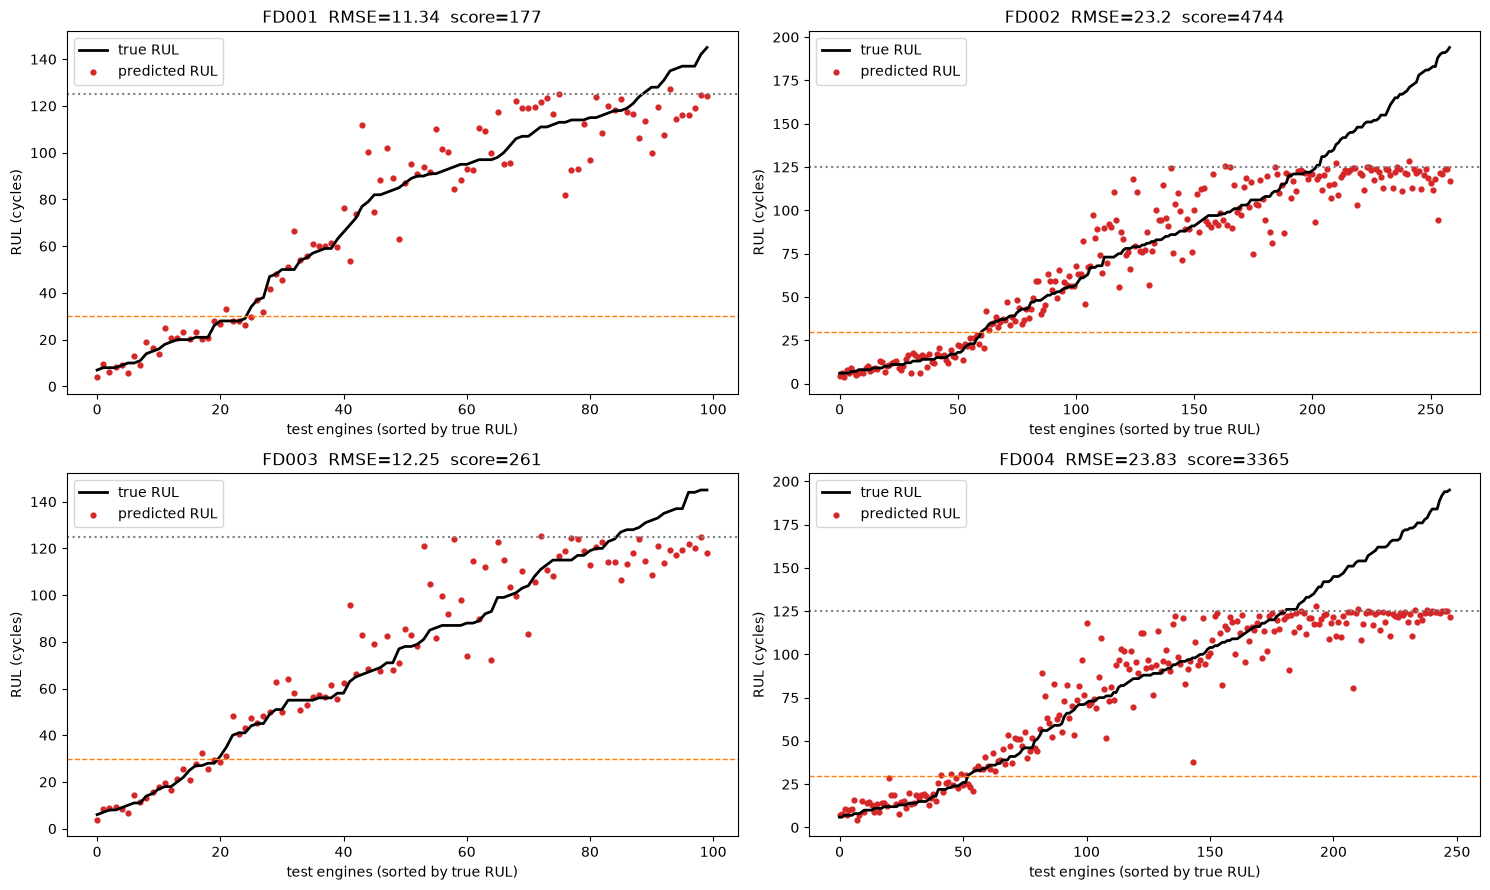

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, fd in zip(axes.ravel(), SUBSETS):
    d = pred_df[pred_df["subset"] == fd].sort_values("true_RUL").reset_index(drop=True)
    ax.plot(d.index, d["true_RUL"], lw=2, color="k", label="true RUL")
    ax.scatter(d.index, d["pred_RUL"], s=12, color="tab:red", label="predicted RUL")
    ax.axhline(CAP, ls=":", c="grey"); ax.axhline(30, ls="--", c="tab:orange", lw=1)
    ax.set_title(f"{fd}  RMSE={res.loc[fd,'RMSE']}  score={res.loc[fd,'NASA_score']:.0f}")
    ax.set_xlabel("test engines (sorted by true RUL)"); ax.set_ylabel("RUL (cycles)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "06_rul_test_predictions.png", bbox_inches="tight")
plt.show()

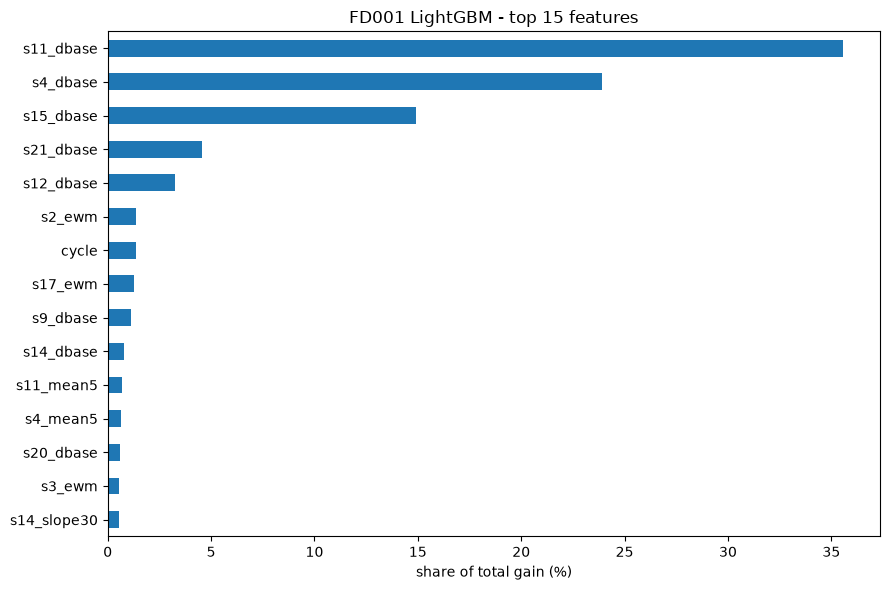

In [7]:
model = joblib.load(MODELS / "lgbm_FD001.joblib")
F = joblib.load(MODELS / "preprocessor_FD001.joblib").feature_names_
imp = pd.Series(model.booster_.feature_importance("gain"), index=F).sort_values(ascending=False)
imp = 100 * imp / imp.sum()
fig, ax = plt.subplots(figsize=(9, 6))
imp.head(15)[::-1].plot.barh(ax=ax, color="tab:blue")
ax.set_xlabel("share of total gain (%)"); ax.set_title("FD001 LightGBM - top 15 features")
fig.tight_layout(); fig.savefig(FIG_DIR / "07_feature_importance_fd001.png", bbox_inches="tight")
plt.show()